# Ajusta cinco modelos cinéticos y compara la proyección del banco

Nivel: 2. Requisitos previos: Nivel 1: Interpreta un banco de flotación como respuesta cinética. Tiempo de lectura: 30 minutos.

## Objetivos

Ejecuta los ajustes no lineales acotados de OreFlow, inspecciona límites y residuales, y compara la predicción de banco con la referencia exacta de tasas distribuidas del motor.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Configura las importaciones y registra versiones. Este paso hace reproducible la ejecución del método.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; escenario nominal Cu-Mo y registro cinético generado en `data/derived/cases/copper_molybdenum.json`, licencia MIT del proyecto. La respuesta es simulada, no medida en planta. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

Los datos batch virtuales mezclan respuestas de primer orden por clase de partícula. OreFlow ajusta formas de primer orden, Kelsall, Klimpel, gamma y exponencial estirada con Levenberg–Marquardt acotado. Luego proyecta cada modelo a un banco; `kinetic_record` es la entrada de producción. Ajuste y proyección son verificaciones diferentes.

Llama al ajustador de producción en un caso resuelto. Esto ejecuta las cinco implementaciones de modelos OreFlow.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
from pipeline.engine.kinetics import kinetic_record

# Paso ejecutable del método OreFlow explicado en la celda anterior.
case = next(item for item in CASES if item.id == 'copper_molybdenum')
result = simulate(case.ore, case.plant, case.nominal)
fits = kinetic_record(result.flotation, result.ore, case.nominal.rougher_cells, result.metrics['rougher_recovery_pct'])
print('status:', fits['status'], '| fitted models:', len(fits.get('models', [])))

status: computed | fitted models: 5


Compara RMSE, convergencia y estado de límites; un parámetro en su límite no se interpreta como un óptimo interior.

In [3]:
# Compara RMSE, convergencia y estado de límites; un parámetro en su límite no se interpreta como un óptimo interior.
summary = pd.DataFrame([{'model': m['id'], 'RMSE (puntos)': m['rmse_pct'],
                          'converged': m['converged'], 'at bound': ', '.join(m['at_bound']) or 'no'}
                         for m in fits['models']])
display(summary.set_index('model').round(4))

,RMSE (puntos),converged,at bound
model,,,
first_order,1.6397,True,no
kelsall,0.0283,True,no
klimpel,0.3976,True,no
gamma,0.1464,True,no
stretched_exponential,0.6667,True,no


Superpone las curvas ajustadas a las observaciones batch virtuales en los mismos tiempos.

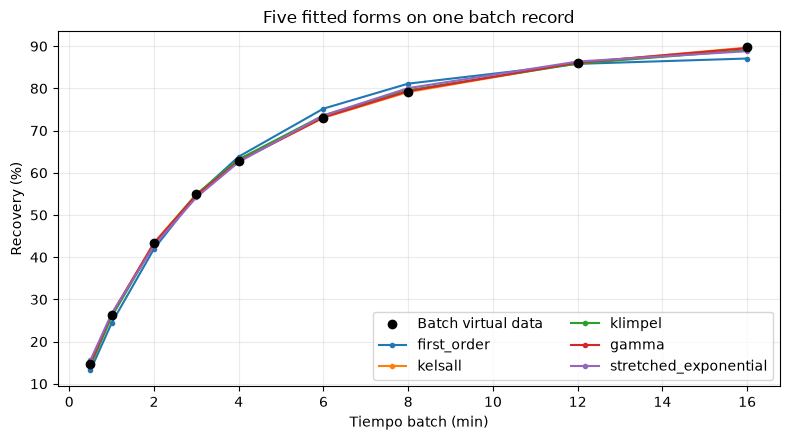

In [4]:
# Superpone las curvas ajustadas a las observaciones batch virtuales en los mismos tiempos.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(fits['times_min'], fits['batch_recovery_pct'], color='black', zorder=4, label='Batch virtual data')
for model in fits['models']:
    ax.plot(fits['times_min'], model['fitted_pct'], marker='.', label=model['id'])
ax.set(xlabel='Tiempo batch (min)', ylabel='Recovery (%)', title='Five fitted forms on one batch record')
ax.grid(True, alpha=.25); ax.legend(ncol=2); fig.tight_layout()

Compara las proyecciones agregadas con el banco exacto de tasas distribuidas e inspecciona la brecha última más allá del último tiempo batch.

In [5]:
# Compara las proyecciones agregadas con el banco exacto de tasas distribuidas e inspecciona la brecha última más allá del último tiempo batch.
projection = pd.DataFrame([{'model': m['id'], 'bank projection (%)': m['bank_projection_pct'],
                              'error vs exact (points)': m['lumping_error_pct'],
                              'ultimate gap (points)': m['ultimate_gap_pct']} for m in fits['models']])
display(projection.round(3))
print('exact bank recovery (%):', fits['bank']['exact_true_flotation_pct'])

,model,bank projection (%),error vs exact (points),ultimate gap (points)
0,first_order,87.393,-6.590,0.471
1,kelsall,92.662,-1.320,4.540
2,klimpel,92.665,-1.318,9.604
3,gamma,92.951,-1.032,7.034
4,stretched_exponential,90.005,-3.977,1.724


exact bank recovery (%): 93.9822410776771


## Resultados

Las curvas muestran la aproximación al registro batch virtual. El error de banco compara predicciones agregadas con la referencia exacta del motor. Un RMSE batch bajo no garantiza un error bajo en la proyección; ninguna de las dos métricas es validación de terreno.

## Resumen

Ejecutaste el ajustador del producto y separaste residual, error de proyección y brecha de extrapolación. Toda la comparación sigue dentro de una prueba virtual generada por el motor.

## Referencias

- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3